In [215]:
import sys
import os
from pathlib import Path
import cv2
import glob
import numpy as np
from PIL import Image
from IPython.display import display, clear_output
from ultralytics import YOLO

# Ensure Python can find local repository scripts
PROJECT_ROOT = Path().resolve()
if (PROJECT_ROOT / "scripts").exists():
    sys.path.insert(0, str(PROJECT_ROOT))
else:
    sys.path.insert(0, str(PROJECT_ROOT.parent))

from scripts.data import read_definitions
from scripts.models import create_adapter

print("Environment and core libraries loaded successfully!")

Environment and core libraries loaded successfully!


In [216]:
# Load anomaly definitions from project root
definitions = read_definitions(PROJECT_ROOT.parent / "scripts" / "anomalies.json")

print("Loading local SmolVLM-256M model into CPU memory...")
vlm_adapter = create_adapter(
    name="smolvlm-256m",
    definitions=definitions,
    cache_dir=None,
    offline=False,
    max_new_tokens=128,  # Increased token limit to prevent mid-sentence cutoffs
    max_side=512
)
print("Local VLM ready for inference!")

Loading local SmolVLM-256M model into CPU memory...
Local VLM ready for inference!


In [217]:
# Create a custom tracker config file with an expanded memory buffer (120 frames)
# This keeps ByteTrack from losing IDs when people bend down or are temporarily blocked.
custom_tracker_content = """
tracker_type: bytetrack
track_high_thresh: 0.5
track_low_thresh: 0.1
new_track_thresh: 0.6
match_thresh: 0.8
track_buffer: 120  
frame_rate: 30
"""

with open("custom_tracker.yaml", "w") as f:
    f.write(custom_tracker_content.strip())

print("✅ Created custom_tracker.yaml with track_buffer = 120")

✅ Created custom_tracker.yaml with track_buffer = 120


In [ ]:
TRACK_HISTORY = {}         
UNATTENDED_ITEMS = {}      

def run_rule_engine(track_id, cls_name, box, frame_id):
    """
    Checks for stationary behavior only after a sustained duration (e.g., 150 frames / ~5 seconds).
    """
    x1, y1, x2, y2 = box
    center_x, center_y = (x1 + x2) / 2, (y1 + y2) / 2
    
    if track_id not in TRACK_HISTORY:
        TRACK_HISTORY[track_id] = {"start_frame": frame_id, "positions": [], "class": cls_name}
    
    TRACK_HISTORY[track_id]["positions"].append((center_x, center_y))
    
    # Keep a rolling window of the last 150 frames (~5 seconds of video)
    window_size = 150
    if len(TRACK_HISTORY[track_id]["positions"]) > window_size:
        TRACK_HISTORY[track_id]["positions"].pop(0)
        positions = TRACK_HISTORY[track_id]["positions"]
        
        # Calculate total displacement from the start of the window
        movement_distance = np.hypot(positions[-1][0] - positions[0][0], positions[-1][1] - positions[0][1])
        
        # Only trigger if they have been in roughly the same spot for the entire window
        duration_active = frame_id - TRACK_HISTORY[track_id]["start_frame"]
        if cls_name == "person" and duration_active > 150 and movement_distance < 40: 
            return True, f"Sustained loitering detected (movement: {movement_distance:.1f}px over {window_size} frames)."
            
    return False, None
  

def check_unattended_objects(boxes, classes, model_names, curr_frame_id):
    """
    Detects abandoned bags with a temporal persistence buffer to prevent flickering 
    when YOLO temporarily drops an object for a few frames.
    """
    person_centers = []
    current_frame_bags = []
    
    for box, cls_idx in zip(boxes, classes):
        cls_name = model_names[cls_idx]
        x1, y1, x2, y2 = box
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        
        if cls_name == "person":
            person_centers.append((cx, cy))
        elif cls_name in ["backpack", "suitcase", "handbag", "bag"]:
            current_frame_bags.append({"box": box, "center": (cx, cy)})
            
    # Track which IDs were seen in this frame
    seen_bag_ids = set()
    alert_triggered = False
    
    for bag in current_frame_bags:
        bx, by = bag["center"]
        is_near_person = False
        
        for px, py in person_centers:
            if np.hypot(bx - px, by - py) < 150:  
                is_near_person = True
                break
                
        # Match bag to existing tracked items or create a stable key based on proximity
        matched_bag_id = None
        for b_id, data in UNATTENDED_ITEMS.items():
            last_bx, last_by = data["last_center"]
            if np.hypot(bx - last_bx, by - last_by) < 50: # Within 50 pixels is the same bag
                matched_bag_id = b_id
                break
                
        if matched_bag_id is None:
            matched_bag_id = f"bag_{int(bx)}_{int(by)}"
            
        seen_bag_ids.add(matched_bag_id)
        
        if not is_near_person:
            if matched_bag_id not in UNATTENDED_ITEMS:
                UNATTENDED_ITEMS[matched_bag_id] = {
                    "start_frame": curr_frame_id,
                    "last_center": (bx, by),
                    "missing_frames": 0
                }
            else:
                # Update position and reset missing counter
                UNATTENDED_ITEMS[matched_bag_id]["last_center"] = (bx, by)
                UNATTENDED_ITEMS[matched_bag_id]["missing_frames"] = 0
            
            # Temporal rule: Must sit unattended for > 90 frames (~3 seconds)
            duration = curr_frame_id - UNATTENDED_ITEMS[matched_bag_id]["start_frame"]
            if duration > 90:
                alert_triggered = True
        else:
            # Owner is near, clear it
            if matched_bag_id in UNATTENDED_ITEMS:
                del UNATTENDED_ITEMS[matched_bag_id]
                
    # Grace period check for bags missing in the current frame
    # Instead of deleting immediately, give it a 15-frame grace period
    inactive_bags = []
    for b_id, data in UNATTENDED_ITEMS.items():
        if b_id not in seen_bag_ids:
            data["missing_frames"] += 1
            if data["missing_frames"] > 15: # Disappeared for more than 15 frames, truly gone
                inactive_bags.append(b_id)
            else:
                # Keep it active during grace period (so timer doesn't reset)
                if (curr_frame_id - data["start_frame"]) > 90:
                    alert_triggered = True
                    
    for b_id in inactive_bags:
        del UNATTENDED_ITEMS[b_id]
                
    if alert_triggered:
        return True, "Possible suspicious activity, send to VLM"
        
    return False, None

print("Tuned rule engines initialized with stricter time thresholds.")

Tuned rule engines initialized with stricter time thresholds.


In [219]:
import glob

# ==========================================
# CONFIGURATION: Point to any target folder!
# ==========================================
TARGET_DIR = PROJECT_ROOT.parent / "data" / "test" 

print(f"Scanning target directory: {TARGET_DIR}")

video_extensions = ('*.avi', '*.mp4', '*.mov', '*.mkv')
video_files = []
for ext in video_extensions:
    video_files.extend(glob.glob(str(TARGET_DIR / ext)))
    video_files.extend(glob.glob(str(TARGET_DIR / "**" / ext), recursive=True))
video_files = sorted(list(set(video_files)))

image_files = []
if not video_files:
    image_extensions = ('*.jpg', '*.JPG', '*.png', '*.PNG', '*.jpeg', '*.JPEG')
    for ext in image_extensions:
        image_files.extend(glob.glob(str(TARGET_DIR / ext)))
        image_files.extend(glob.glob(str(TARGET_DIR / "**" / ext), recursive=True))
    image_files = sorted(list(set(image_files)))

frame_id = 0
image_paths = []
is_video = False

if video_files:
    is_video = True
    SELECTED_VIDEO = video_files[0]
    print(f"🎬 Automatically detected video stream: {SELECTED_VIDEO}")
    cap = cv2.VideoCapture(SELECTED_VIDEO)
    if not cap.isOpened():
        raise FileNotFoundError(f"❌ Could not open video file at {SELECTED_VIDEO}")
elif image_files:
    is_video = False
    image_paths = image_files
    print(f"📸 Automatically detected image sequence! Loaded {len(image_paths)} frames.")
else:
    raise ValueError(f"❌ No valid video or image files found in: {TARGET_DIR}")

def get_next_frame():
    global frame_id
    if is_video:
        ret, frame = cap.read()
        if not ret:
            return None
        curr_id = frame_id
        frame_id += 1
        return curr_id, frame
    else:
        if frame_id >= len(image_paths):
            return None
        frame = cv2.imread(image_paths[frame_id])
        curr_id = frame_id
        frame_id += 1
        return curr_id, frame

Scanning target directory: /Users/ianvarella/capstone_S25/data/test
🎬 Automatically detected video stream: /Users/ianvarella/capstone_S25/data/test/video8_kBrfBtsN.avi


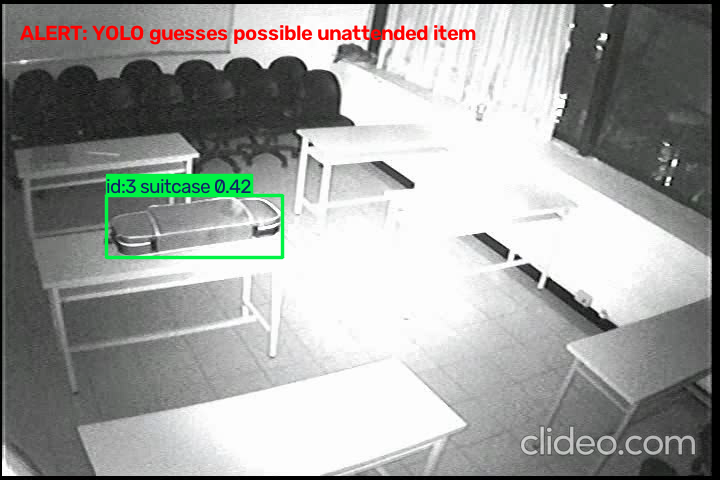

In [ ]:
import concurrent.futures

model = YOLO("yolo26m.pt")  # Medium model variant
ANOMALY_LOGS = []
frame_id = 0

vlm_executor = concurrent.futures.ThreadPoolExecutor(max_workers=1)
last_vlm_trigger_frame = {}
COOLDOWN_FRAMES = 150  # Halved since we are sampling every 2nd frame

def background_vlm_task(crop_bgr, curr_frame_id, track_id):
    try:
        crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
        prediction = vlm_adapter.predict(Image.fromarray(crop_rgb))
        raw_text = getattr(prediction, 'raw', str(prediction))
        parsed_label = getattr(prediction, 'label', None)
        
        ANOMALY_LOGS.append({"frame": curr_frame_id, "track_id": track_id, "vlm_label": parsed_label, "raw_output": raw_text})
        print(f"\n🔍 [VLM DEBUG] Frame {curr_frame_id} (ID {track_id}) -> {parsed_label}")
    except Exception as e:
        print(f"\n[BACKGROUND AI ERROR] Frame {curr_frame_id}: {e}")

print("▶️ Starting optimized pipeline with frame sampling & downsampling...\n")

while True:
    res = get_next_frame()
    if res is None:
        print("End of data stream reached.")
        break
    curr_frame_id, frame = res
    if frame is None:
        continue
        
    # ==========================================
    # 1. RESOLUTION DOWNSAMPLING (Speed up OpenCV & Display)
    # Resize 1080p down to 720p width (maintains aspect ratio)
    # ==========================================
    h, w, _ = frame.shape
    if w > 1280:
        scale = 1280 / w
        frame = cv2.resize(frame, (1280, int(h * scale)))

    # ==========================================
    # 2. FRAME SAMPLING (Process every 5th frame)
    # ==========================================
    if curr_frame_id % 3 != 0:
        continue  # Skip this frame for heavy AI, keeps the video flowing fast!

    # Run YOLO26 medium + ByteTrack
    results = model.track(frame, persist=True, tracker="bytetrack.yaml", conf=0.30, verbose=False)
    
    # Filter out furniture
    IGNORED_CLASSES = {"bench", "dining table", "chair", "couch", "bed", "tv", "refrigerator", "stool", "desk"}
    if results[0].boxes is not None and results[0].boxes.id is not None:
        valid_indices = [
            i for i, cls_idx in enumerate(results[0].boxes.cls.int().cpu().numpy())
            if model.names[cls_idx] not in IGNORED_CLASSES
        ]
        results[0].boxes = results[0].boxes[valid_indices]

    annotated_frame = results[0].plot()
    
    status_text = f"Frame {curr_frame_id} | Status: Live Monitoring (Sampled)"
    status_color = (0, 255, 0)
    
    if results[0].boxes is not None and results[0].boxes.id is not None:
        boxes = results[0].boxes.xyxy.cpu().numpy()
        track_ids = results[0].boxes.id.int().cpu().numpy()
        classes = results[0].boxes.cls.int().cpu().numpy()
        
        bag_triggered, bag_reason = check_unattended_objects(boxes, classes, model.names, curr_frame_id)
        if bag_triggered:
            status_color = (0, 0, 255)
            status_text = f"ALERT: {bag_reason}"
            
        for box, track_id, cls_idx in zip(boxes, track_ids, classes):
            cls_name = model.names[cls_idx]
            is_triggered, trigger_reason = run_rule_engine(track_id, cls_name, box, curr_frame_id)
            
            if is_triggered or bag_triggered:
                if not bag_triggered:
                    status_color = (0, 0, 255)
                    status_text = f"ALERT [ID {track_id}]: {trigger_reason}"
                
                last_frame = last_vlm_trigger_frame.get(track_id, -999)
                if curr_frame_id - last_frame > COOLDOWN_FRAMES:
                    last_vlm_trigger_frame[track_id] = curr_frame_id
                    
                    x1, y1, x2, y2 = map(int, box)
                    fh, fw, _ = frame.shape
                    crop = frame[max(0, y1 - 10) : min(fh, y2 + 50), max(0, x1 - 30) : min(fw, x2 + 30)].copy()
                    
                    if crop.size > 0:
                        vlm_executor.submit(background_vlm_task, crop, curr_frame_id, track_id)

    cv2.putText(annotated_frame, status_text, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.7, status_color, 2, cv2.LINE_AA)
    clear_output(wait=True)
    display(Image.fromarray(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)))

if is_video:
    cap.release()
vlm_executor.shutdown(wait=True)
print("Pipeline execution complete.")